In [ ]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [ ]:

import pandas as pd
import numpy as np
import re
import time
import matplotlib.pyplot as plt

from nltk.stem import SnowballStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

df = pd.read_csv("spam.csv", encoding="latin-1")

# Keep only the label and message columns
df = df.iloc[:, :2].copy()
df.columns = ["label", "message"]

# Remove missing or empty messages
df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[
    df["label"].isin(["ham", "spam"]) &
    (df["message"] != "")
].reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nFirst five messages:")
display(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nClass percentages:")
print(
    (df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

Dataset shape: (5572, 2)

First five messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


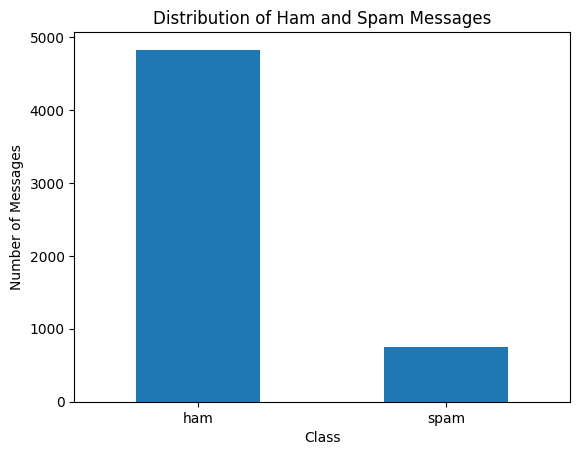

In [ ]:

df["label"].value_counts().reindex(
    ["ham", "spam"]
).plot(kind="bar")

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [ ]:

stemmer = SnowballStemmer("english")

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Tokenization: split text into words
    words = re.findall(r"\b[a-z]+\b", text)

    # Stemming: reduce words to their root form
    words = [stemmer.stem(word) for word in words]

    return " ".join(words)

df["clean_message"] = df["message"].apply(preprocess_text)

print("Original message:")
print(df["message"].iloc[0])

print("\nPreprocessed message:")
print(df["clean_message"].iloc[0])

Original message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Preprocessed message:
go until jurong point crazi avail onli in bugi n great world la e buffet cine there got amor wat


In [ ]:

X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


In [ ]:

def stem_tokens(text):
    tokens = re.findall(r"\b[a-z]+\b", text.lower())
    return [stemmer.stem(word) for word in tokens]

tfidf = TfidfVectorizer(
    tokenizer=stem_tokens,
    token_pattern=None,
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['abov', 'afterward', 'alon', 'alreadi', 'alway', 'ani', 'anoth', 'anyon', 'anyth', 'anywher', 'becam', 'becaus', 'becom', 'befor', 'besid', 'cri', 'describ', 'dure', 'els', 'elsewher', 'empti', 'everi', 'everyon', 'everyth', 'everywher', 'fifti', 'forti', 'henc', 'hereaft', 'herebi', 'howev', 'hundr', 'inde', 'mani', 'meanwhil', 'moreov', 'nobodi', 'noon', 'noth', 'nowher', 'onc', 'onli', 'otherwis', 'ourselv', 'perhap', 'pleas', 'sever', 'sinc', 'sincer', 'sixti', 'someon', 'someth', 'sometim', 'somewher', 'themselv', 'thenc', 'thereaft', 'therebi', 'therefor', 'togeth', 'twelv', 'twenti', 'veri', 'whatev', 'whenc', 'whenev', 'wherea', 'whereaft', 'wherebi', 'wherev', 'whi', 'yourselv'] not in stop_words.
  warnings.warn(


Training feature matrix: (4457, 5000)
Testing feature matrix: (1115, 5000)
Number of TF-IDF features: 5000


In [ ]:

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB()
}

results = []
predictions = {}

for name, model in models.items():

    # Measure training time
    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    train_time = time.perf_counter() - start

    # Measure testing/prediction time
    start = time.perf_counter()
    y_pred = model.predict(X_test_tfidf)
    test_time = time.perf_counter() - start

    predictions[name] = y_pred

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="spam",
            zero_division=0
        ),
        "Training Time (s)": train_time,
        "Testing Time (s)": test_time
    })

    print(f"{name} trained successfully!")

print("\nAll four models have been trained.")

Decision Tree trained successfully!
KNN trained successfully!
SVM trained successfully!
Naive Bayes trained successfully!

All four models have been trained.


In [ ]:

results_df = pd.DataFrame(results)

print("Comparative Performance Table")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Training Time (s)": "{:.4f}",
        "Testing Time (s)": "{:.4f}"
    })
)

Comparative Performance Table


,Algorithm,Accuracy,Precision,Recall,F1-Score,Training Time (s),Testing Time (s)
0,Decision Tree,0.9561,0.8425,0.8255,0.8339,0.8581,0.0017
1,KNN,0.9659,0.9370,0.7987,0.8623,0.0177,0.3817
2,SVM,0.9812,0.9848,0.8725,0.9253,0.0261,0.0008
3,Naive Bayes,0.9650,0.9911,0.7450,0.8506,0.0328,0.0009


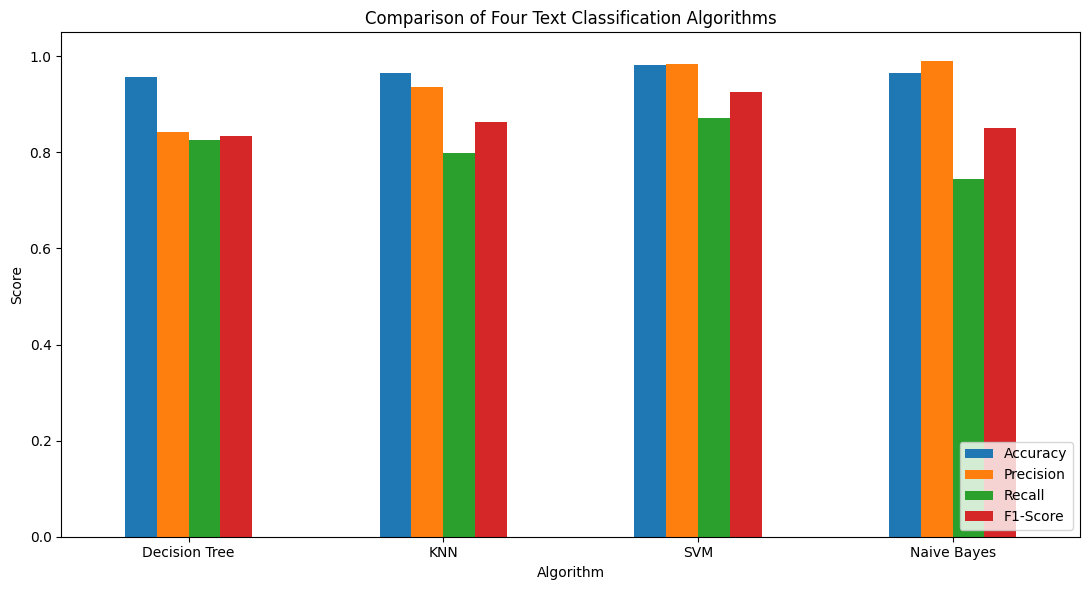

In [ ]:

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Four Text Classification Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Best model: SVM

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       0.98      0.87      0.93       149

    accuracy                           0.98      1115
   macro avg       0.98      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115



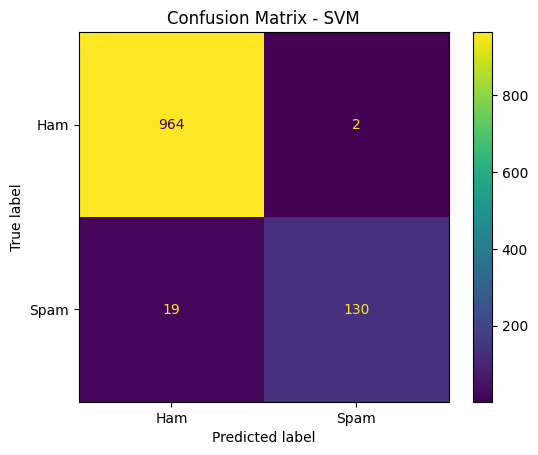

In [ ]:

best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(),
    "Algorithm"
]

best_predictions = predictions[best_model_name]

print("Best model:", best_model_name)
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=["ham", "spam"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["ham", "spam"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

,K,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,3,0.9641,0.9160,0.8054,0.8571,0.0130
1,5,0.9659,0.9370,0.7987,0.8623,0.0116
2,7,0.9668,0.9516,0.7919,0.8645,0.0118


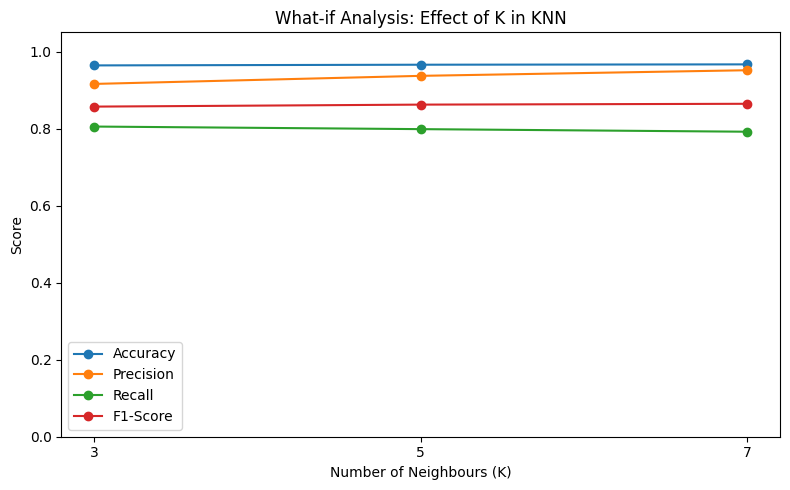

In [ ]:

knn_results = []

for k in [3, 5, 7]:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    start = time.perf_counter()
    knn.fit(X_train_tfidf, y_train)
    training_time = time.perf_counter() - start

    pred = knn.predict(X_test_tfidf)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, pos_label="spam",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, pos_label="spam",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred, pos_label="spam",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df.round(4))

knn_results_df.set_index("K")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(marker="o", figsize=(8, 5))

plt.title("What-if Analysis: Effect of K in KNN")
plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks([3, 5, 7])
plt.tight_layout()
plt.show()

In [ ]:

results_df.to_csv(
    "classifier_comparison.csv",
    index=False
)

knn_results_df.to_csv(
    "knn_what_if_results.csv",
    index=False
)

from google.colab import files

files.download("classifier_comparison.csv")
files.download("knn_what_if_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>